# Tugas Praktikum - CNN CIFAR-10 > 80% dan CNN MNIST

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js14-convolutional-neural-network/tugas-praktimum)

1. Modifikasi model CNN pada Praktikum 2 sehingga akurasi testing lebih dari 80%.
2. Buat model CNN untuk klasifikasi dataset MNIST.

Data test **tidak dipakai** untuk memilih epoch. Pada modul, data test dipakai sebagai `validation_data`; di sini 5.000 citra latih terakhir
dipisahkan sebagai validasi untuk EarlyStopping, dan data test hanya dievaluasi sekali di akhir.

In [1]:
import sys
import numpy as np
import tensorflow as tf
tf.keras.utils.set_random_seed(42)
print("Kernel:", sys.executable)
print("TensorFlow:", tf.__version__)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python
TensorFlow: 2.21.0


## Bagian 1 - Modifikasi CNN CIFAR-10

In [2]:
import time
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras import datasets, layers, models

(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()
train_images, test_images = train_images / 255.0, test_images / 255.0
x_tr, y_tr = train_images[:45000], train_labels[:45000]
x_val, y_val = train_images[45000:], train_labels[45000:]
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

Modifikasi terhadap model Praktikum 2 dan alasannya:

| Modifikasi | Alasan / rujukan |
| --- | --- |
| Blok konvolusi bergaya VGG: dua Conv 3×3 per blok, filter 32 → 64 → 128, `padding='same'` | Tumpukan kernel 3×3 memperluas *receptive field* dengan parameter lebih sedikit (Simonyan & Zisserman, 2015) |
| Batch Normalization setelah setiap konvolusi | Menstabilkan distribusi aktivasi sehingga pelatihan lebih cepat dan dapat memakai learning rate lebih besar (Ioffe & Szegedy, 2015) |
| Dropout 0,2-0,5 bertingkat | Mengurangi overfitting yang terlihat pada model modul (Srivastava dkk., 2014) |
| Augmentasi flip horizontal, translasi, dan rotasi kecil | Menambah variasi data latih CIFAR-10 (Shorten & Khoshgoftaar, 2019) |
| EarlyStopping dan ReduceLROnPlateau pada data validasi | Memilih epoch tanpa melihat data test |

In [3]:
tf.keras.utils.set_random_seed(42)
augment = models.Sequential([layers.RandomFlip('horizontal'), layers.RandomTranslation(0.1, 0.1), layers.RandomRotation(0.05)], name='augmentasi')

def conv_block(filters, drop):
    return [layers.Conv2D(filters, (3, 3), padding='same', use_bias=False), layers.BatchNormalization(), layers.Activation('relu'),
            layers.Conv2D(filters, (3, 3), padding='same', use_bias=False), layers.BatchNormalization(), layers.Activation('relu'),
            layers.MaxPooling2D((2, 2)), layers.Dropout(drop)]

model = models.Sequential([layers.Input(shape=(32, 32, 3)), augment]
                          + conv_block(32, 0.2) + conv_block(64, 0.3) + conv_block(128, 0.4)
                          + [layers.Flatten(), layers.Dense(128, use_bias=False), layers.BatchNormalization(),
                             layers.Activation('relu'), layers.Dropout(0.5), layers.Dense(10)])
model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentasi (Sequential)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 552,298 (2.11 MB)

 Trainable params: 551,146 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [4]:
callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True),
             tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5)]
t0 = time.perf_counter()
history = model.fit(x_tr, y_tr, epochs=60, batch_size=64, validation_data=(x_val, y_val), callbacks=callbacks, verbose=2)
train_time = time.perf_counter() - t0
print(f'Waktu latih: {train_time/60:.1f} menit, epoch dijalankan: {len(history.history["loss"])}')

Epoch 1/60


704/704 - 45s - 64ms/step - accuracy: 0.3830 - loss: 1.7190 - val_accuracy: 0.4476 - val_loss: 1.5983 - learning_rate: 0.0010


Epoch 2/60


704/704 - 50s - 71ms/step - accuracy: 0.5153 - loss: 1.3488 - val_accuracy: 0.5412 - val_loss: 1.3667 - learning_rate: 0.0010


Epoch 3/60


704/704 - 54s - 77ms/step - accuracy: 0.5803 - loss: 1.1870 - val_accuracy: 0.5812 - val_loss: 1.3695 - learning_rate: 0.0010


... (79 outputs left out)

704/704 - 57s - 80ms/step - accuracy: 0.8332 - loss: 0.4897 - val_accuracy: 0.8586 - val_loss: 0.4187 - learning_rate: 1.5625e-05


Epoch 44/60


704/704 - 54s - 77ms/step - accuracy: 0.8330 - loss: 0.4919 - val_accuracy: 0.8590 - val_loss: 0.4221 - learning_rate: 1.5625e-05


Waktu latih: 39.8 menit, epoch dijalankan: 44


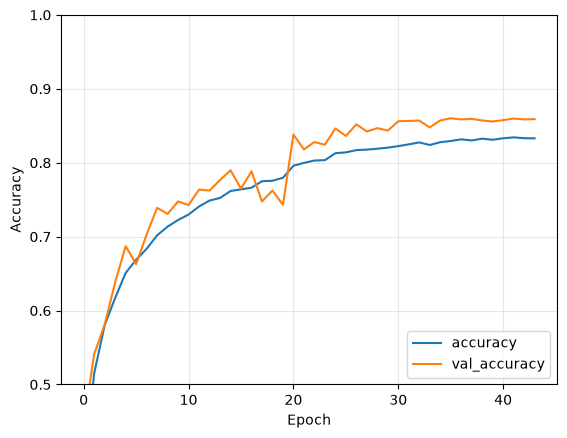

313/313 - 3s - 9ms/step - accuracy: 0.8523 - loss: 0.4385


Akurasi testing: 0.8523 (> 80%)


In [5]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.ylim([0.5, 1]); plt.legend(loc='lower right'); plt.grid(alpha=.3); plt.show()

test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print(f'Akurasi testing: {test_acc:.4f}', '(> 80%)' if test_acc > 0.80 else '(belum > 80%)')

              precision    recall  f1-score   support

    airplane     0.8483    0.8950    0.8710      1000
  automobile     0.9114    0.9670    0.9384      1000
        bird     0.8753    0.7440    0.8043      1000
         cat     0.8165    0.6630    0.7318      1000
        deer     0.8253    0.8550    0.8399      1000
         dog     0.8351    0.7240    0.7756      1000
        frog     0.7583    0.9540    0.8450      1000
       horse     0.8642    0.9040    0.8837      1000
        ship     0.9247    0.8970    0.9107      1000
       truck     0.8804    0.9200    0.8998      1000

    accuracy                         0.8523     10000
   macro avg     0.8540    0.8523    0.8500     10000
weighted avg     0.8540    0.8523    0.8500     10000



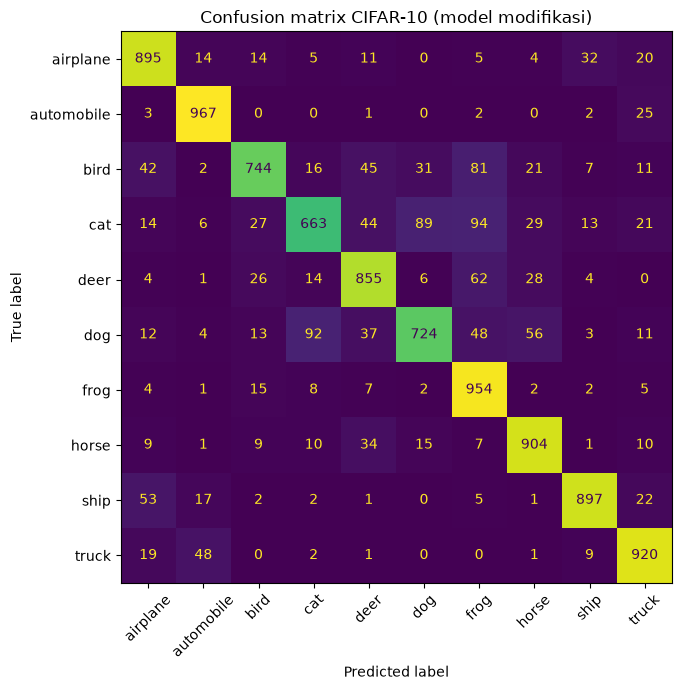

In [6]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
pred = model.predict(test_images, verbose=0).argmax(1)
print(classification_report(test_labels.ravel(), pred, target_names=class_names, digits=4))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(test_labels.ravel(), pred, display_labels=class_names, ax=ax, colorbar=False, xticks_rotation=45)
plt.title('Confusion matrix CIFAR-10 (model modifikasi)'); plt.tight_layout(); plt.show()

### Perbandingan dengan model Praktikum 2

| Model | Parameter | Epoch | Akurasi test |
| --- | --- | --- | --- |
| CNN Praktikum 2 (modul) | 122.570 | 10 | 68,95% |
| **CNN modifikasi (VGG-style + BN + Dropout + augmentasi)** | 552.298 | 44 (terbaik: 36) | **85,23%** |

Target **> 80% tercapai: akurasi test 85,23%**, naik 16,3 poin dari model modul. EarlyStopping berhenti di epoch 44 dan mengembalikan bobot epoch 36 (akurasi validasi 86,02%). Waktu latih 39,8 menit di CPU Apple M4.

* **Overfitting teratasi.** Pada model modul, akurasi train 80,6% jauh di atas test 68,9%. Pada model modifikasi, akurasi train (83,3%) justru sedikit di bawah validasi (85,9%). Ini wajar karena akurasi train dihitung dengan dropout dan augmentasi aktif, sedangkan validasi tidak. Regularisasi dropout (Srivastava dkk., 2014) dan augmentasi (Shorten & Khoshgoftaar, 2019) bekerja sesuai tujuannya.
* **Kedalaman dan BN.** Enam konvolusi 3×3 dalam tiga blok memberi *receptive field* yang lebih luas dengan parameter efisien (Simonyan & Zisserman, 2015). Batch Normalization (Ioffe & Szegedy, 2015) membuat jaringan 6 konvolusi ini tetap stabil dilatih dengan Adam default.
* **Per kelas.** Semua kelas membaik. `cat` naik dari recall 0,39 ke 0,66 dan `bird` dari 0,48 ke 0,74. Kucing dan anjing tetap menjadi pasangan tersulit (F1 0,73 dan 0,78), sesuai pola umum CIFAR-10 (Krizhevsky, 2009).
* **Catatan GPU.** Training sempat dicoba di GPU Apple M4 dengan `tensorflow-metal` 1.2.0. GPU sekitar 1,85× lebih cepat, tetapi menghasilkan pelatihan yang salah: MLP MNIST hanya 74% dibanding 96,9% di CPU. Karena itu hasil akhir di atas memakai CPU.

## Bagian 2 - CNN untuk MNIST

Arsitektur mengikuti pola Praktikum 2 (Conv 32 → Pool → Conv 64 → Pool → Conv 64 → Flatten → Dense 64 → Dense 10 logits),
dengan input 28×28×1. Hasilnya dibandingkan dengan JST/MLP dari Tugas JS13 pada data dan epoch yang sama.

In [7]:
tf.keras.utils.set_random_seed(42)
(mx_train, my_train), (mx_test, my_test) = datasets.mnist.load_data()
mx_train = (mx_train / 255.0)[..., None]; mx_test = (mx_test / 255.0)[..., None]

mnist_cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'), layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'), layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(), layers.Dense(64, activation='relu'), layers.Dense(10)])
mnist_cnn.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])
mnist_cnn.summary()
t0 = time.perf_counter()
mh = mnist_cnn.fit(mx_train, my_train, epochs=10, batch_size=32, validation_split=0.1, verbose=2)
cnn_time = time.perf_counter() - t0
cnn_loss, cnn_acc = mnist_cnn.evaluate(mx_test, my_test, verbose=0)
print(f'Akurasi test CNN MNIST: {cnn_acc:.4f}')

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,322 (364.54 KB)

 Trainable params: 93,322 (364.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


... (16 outputs left out)

1688/1688 - 7s - 4ms/step - accuracy: 0.9966 - loss: 0.0100 - val_accuracy: 0.9867 - val_loss: 0.0621


Epoch 10/10


1688/1688 - 7s - 4ms/step - accuracy: 0.9970 - loss: 0.0093 - val_accuracy: 0.9873 - val_loss: 0.0768


Akurasi test CNN MNIST: 0.9876


In [8]:
tf.keras.utils.set_random_seed(42)
mlp = models.Sequential([layers.Input(shape=(28, 28, 1)), layers.Flatten(), layers.Dense(128, activation='relu'),
                         layers.Dense(64, activation='relu'), layers.Dense(10)])
mlp.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])
t0 = time.perf_counter()
mlp.fit(mx_train, my_train, epochs=10, batch_size=32, validation_split=0.1, verbose=0)
mlp_time = time.perf_counter() - t0
mlp_loss, mlp_acc = mlp.evaluate(mx_test, my_test, verbose=0)

pd.DataFrame([
    {'model': 'MLP 128-64 (Tugas JS13)', 'parameter': mlp.count_params(), 'test_acc': mlp_acc, 'test_error_%': 100 * (1 - mlp_acc), 'waktu_latih_s': mlp_time},
    {'model': 'CNN 32-64-64 (pola Praktikum 2)', 'parameter': mnist_cnn.count_params(), 'test_acc': cnn_acc, 'test_error_%': 100 * (1 - cnn_acc), 'waktu_latih_s': cnn_time},
]).set_index('model').round(4)

,parameter,test_acc,test_error_%,waktu_latih_s
model,,,,
MLP 128-64 (Tugas JS13),109386,0.9706,2.94,9.0015
CNN 32-64-64 (pola Praktikum 2),93322,0.9876,1.24,68.7065


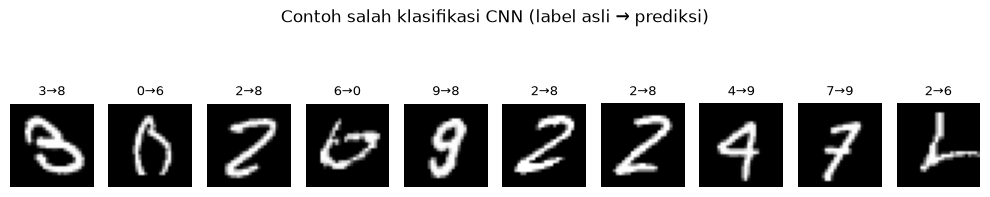

In [9]:
import numpy as np
pred_m = mnist_cnn.predict(mx_test, verbose=0).argmax(1)
wrong = np.where(pred_m != my_test)[0][:10]
plt.figure(figsize=(10, 2.5))
for k, i in enumerate(wrong):
    plt.subplot(1, 10, k + 1); plt.imshow(mx_test[i, ..., 0], cmap='gray'); plt.axis('off')
    plt.title(f'{my_test[i]}→{pred_m[i]}', fontsize=9)
plt.suptitle('Contoh salah klasifikasi CNN (label asli → prediksi)'); plt.tight_layout(); plt.show()

### Analisis CNN vs MLP pada MNIST

| Model | Parameter | Akurasi test | Error test | Waktu latih 10 epoch |
| --- | --- | --- | --- | --- |
| MLP 128-64 (Tugas JS13) | 109.386 | 97,06% | 2,94% | 9,0 s |
| **CNN 32-64-64 (pola Praktikum 2)** | **93.322** | **98,76%** | **1,24%** | 68,7 s |

* **CNN mengurangi kesalahan 58%** (2,94% → 1,24%) dengan parameter **15% lebih sedikit**. MLP meratakan citra menjadi vektor 784 sehingga informasi tetangga piksel hilang, sedangkan CNN berbagi bobot kernel di seluruh posisi citra. Sifat *local receptive field* dan *weight sharing* inilah yang menjadi motivasi LeNet (LeCun dkk., 1998).
* **Biaya komputasi.** Waktu latih CNN 7,6 kali lebih lama karena setiap kernel dikonvolusikan di semua posisi, walaupun jumlah parameternya lebih kecil. Jumlah parameter tidak sama dengan jumlah operasi.
* **Literatur.** LeCun dkk. (1998) melaporkan error LeNet-5 0,95%, dan 0,8% dengan distorsi data. Simard dkk. (2003) mencapai 0,4% dengan CNN + augmentasi elastis. Model sederhana ini (1,24%) sudah mendekati LeNet-5. Selisihnya kemungkinan dapat ditutup dengan augmentasi atau dropout, karena akurasi train (99,7%) masih di atas validasi (98,7%).

## Rujukan

1. Simonyan, K., & Zisserman, A. (2015). Very deep convolutional networks for large-scale image recognition. *International Conference on Learning Representations (ICLR)*. https://arxiv.org/abs/1409.1556
2. Ioffe, S., & Szegedy, C. (2015). Batch normalization: Accelerating deep network training by reducing internal covariate shift. *Proceedings of the 32nd ICML*, PMLR 37, 448-456.
3. Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research*, 15(56), 1929-1958.
4. Shorten, C., & Khoshgoftaar, T. M. (2019). A survey on image data augmentation for deep learning. *Journal of Big Data*, 6, 60. https://doi.org/10.1186/s40537-019-0197-0
5. Krizhevsky, A. (2009). *Learning Multiple Layers of Features from Tiny Images* (Technical Report). University of Toronto.
6. LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). Gradient-based learning applied to document recognition. *Proceedings of the IEEE*, 86(11), 2278-2324. https://doi.org/10.1109/5.726791
7. Simard, P. Y., Steinkraus, D., & Platt, J. C. (2003). Best practices for convolutional neural networks applied to visual document analysis. *Proceedings of the 7th ICDAR*, 958-963. https://doi.org/10.1109/ICDAR.2003.1227801